# Checkpoint — Dimensie reductie

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `n_components_secom` — aantal PCA-componenten dat 95% van de variantie behoudt voor SECOM (int)
- `reduction_pct_secom` — procent datareductie voor SECOM (float)
- `X_pca_secom` — de gereduceerde data van SECOM (evenveel rijen als de oorspronkelijke data, `n_components_secom` kolommen)
- `n_components_steel` — aantal PCA-componenten dat 95% van de variantie behoudt voor Steel Plates (int)
- `reduction_pct_steel` — procent datareductie voor Steel Plates (float)
- `X_pca_steel` — de gereduceerde data van Steel Plates
- `n_components_aps` — aantal PCA-componenten dat 95% van de variantie behoudt voor APS (int)
- `reduction_pct_aps` — procent datareductie voor APS (float)
- `X_pca_aps` — de gereduceerde data van APS
- `antwoord_scaling` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_95` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik voor elke dataset `PCA(n_components=0.95)` op de **gestandaardiseerde** data (met `StandardScaler`). De datareductie bereken je als `(1 - aantal_componenten / oorspronkelijk_aantal_features) * 100`.

De datasets staan lokaal in `data/` (er wordt niets gedownload).


## Oefening 1 — SECOM

De SECOM-dataset bevat 590 sensormetingen van halfgeleiderproductie. Het bestand bevat veel ontbrekende waarden; vul ze in met het kolomgemiddelde.

Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_secom`, de gereduceerde data in `X_pca_secom` en de procentuele datareductie in `reduction_pct_secom`.


In [1]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/secom/secom.data"
labels_path = "data/secom/secom_labels.data"

# Dataset laden (spatie is de separator in SECOM)
X = pd.read_csv(data_path, sep="\\s+", header=None)
y = pd.read_csv(labels_path, sep="\\s+", header=None, usecols=[0])  # labels in eerste kolom

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [12]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_secom, de gereduceerde
# data in X_pca_secom en de procentuele datareductie in reduction_pct_secom.
pca = PCA(n_components=0.95).fit(X_scaled)
n_components_secom = len(pca.components_)
X_pca_secom = pca.transform(X_scaled)
reduction_pct_secom = (1 - n_components_secom / X_scaled.shape[1]) * 100
reduction_pct_secom

71.1864406779661

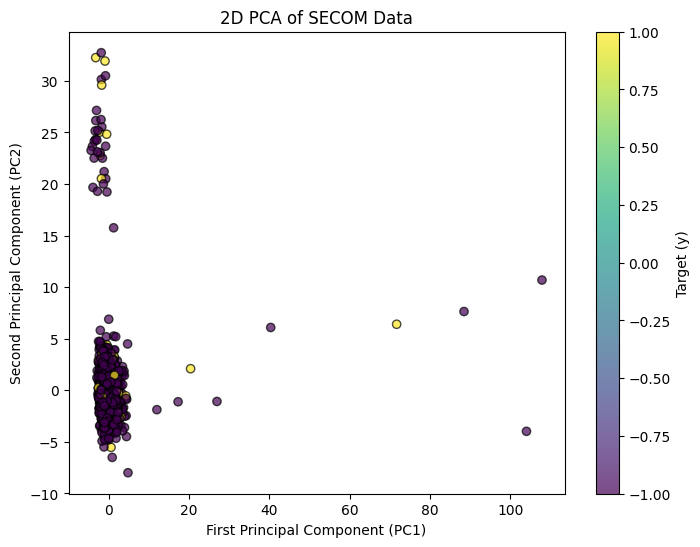

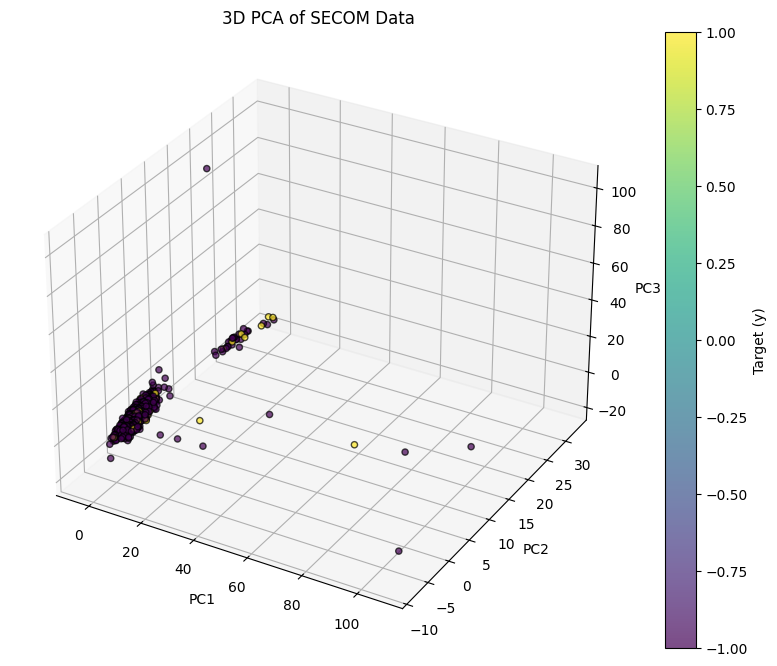

In [13]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam). Tip: fit hiervoor opnieuw een
# PCA met n_components=2 en n_components=3 en kleur de punten met y.
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
plt.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1], c=y, cmap='viridis', edgecolor='k', alpha=0.7)
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('2D PCA of SECOM Data')
plt.colorbar(label='Target (y)')
plt.show()

# --- 3D PCA Plot ---
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')
scatter = ax.scatter(X_pca_3d[:, 0], X_pca_3d[:, 1], X_pca_3d[:, 2], c=y, cmap='viridis', edgecolor='k', alpha=0.7)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('3D PCA of SECOM Data')
fig.colorbar(scatter, label='Target (y)')
plt.show()


## Oefening 2 — Steel Plates Faults

De Steel Plates Faults-dataset bevat 27 metingen van staalplaten. De kolomnamen staan in `data/steel_plates/Faults27x7_var`; de laatste 7 kolommen zijn binaire foutlabels.

Pas PCA toe zodat **95% van de variantie behouden blijft** op de 27 meetkolommen. Bewaar het aantal componenten in `n_components_steel`, de gereduceerde data in `X_pca_steel` en de procentuele datareductie in `reduction_pct_steel`.


In [14]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Pad naar bestanden
data_path = "data/steel_plates/Faults.NNA"
names_path = "data/steel_plates/Faults27x7_var"

# Kolomnamen laden
with open(names_path, "r") as f:
    colnames = [line.strip() for line in f.readlines()]

# Data laden
df = pd.read_csv(data_path, sep="\\s+", header=None, names=colnames)

# Eerste 27 kolommen zijn de metingen, de laatste 7 zijn binaire foutlabels
X = df.iloc[:, :27]
y = df.iloc[:, 27:]

# Ontbrekende waarden invullen met het kolomgemiddelde
X = X.fillna(X.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [15]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_steel, de gereduceerde
# data in X_pca_steel en de procentuele datareductie in reduction_pct_steel.
pca = PCA(n_components=0.95).fit(X_scaled)
n_components_steel = len(pca.components_)
X_pca_steel = pca.transform(X_scaled)
reduction_pct_steel = (1 - n_components_steel / X_scaled.shape[1]) * 100
reduction_pct_steel

51.85185185185186

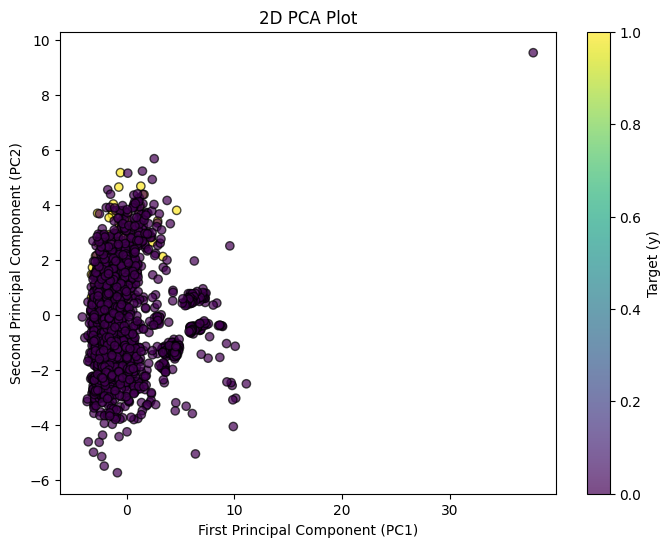

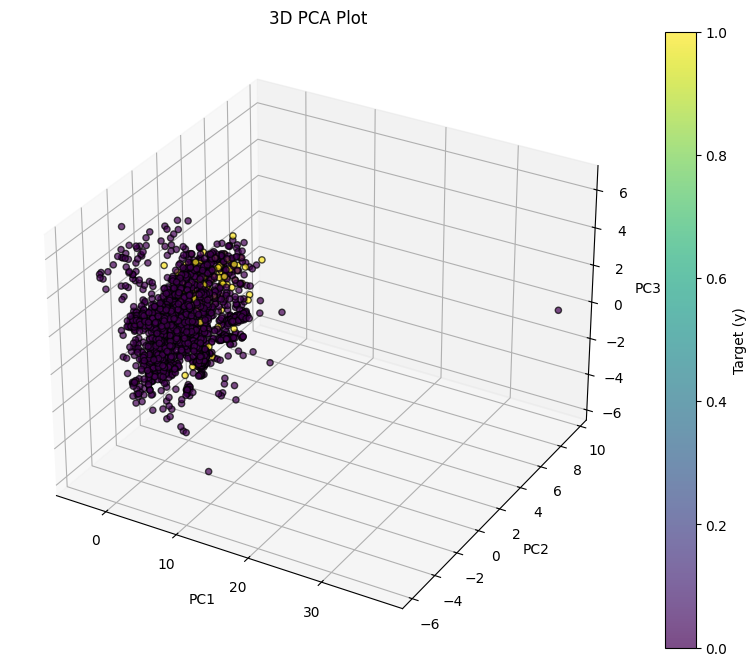

In [18]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van
# X_scaled (niet gecheckt, maar leerzaam).
# Convert y DataFrame to a numeric array or take the first/relevant label column if needed
# If y contains multiple binary columns, you can sum them or pick a specific column to color by, 
# or convert the whole DataFrame to integers:
y_numeric = y.astype(int).to_numpy()

# If you want to plot coloring by the sum of faults or a specific fault column (e.g., the first one):
# y_numeric = y.iloc[:, 0] # Use this if you want to color by just the first fault type

# --- 2D PCA Plot ---
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
# If y_numeric has multiple columns, we can color by the first column for simplicity:
c_values = y_numeric[:, 0] if y_numeric.ndim > 1 else y_numeric

scatter_2d = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=c_values,
    cmap='viridis',
    edgecolor='k',
    alpha=0.7,
)
plt.xlabel('First Principal Component (PC1)')
plt.ylabel('Second Principal Component (PC2)')
plt.title('2D PCA Plot')
plt.colorbar(scatter_2d, label='Target (y)')
plt.show()

# --- 3D PCA Plot ---
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')
scatter_3d = ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=c_values,
    cmap='viridis',
    edgecolor='k',
    alpha=0.7,
)

ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('3D PCA Plot')
fig.colorbar(scatter_3d, label='Target (y)')
plt.show()

## Oefening 3 — APS Failure at Scania Trucks

De APS-dataset bevat 170 sensormetingen van vrachtwagens. De eerste 20 regels van de CSV-bestanden zijn metadata; de testset bevat geen labels.

Combineer train en test, vul ontbrekende waarden in en standaardiseer. Pas PCA toe zodat **95% van de variantie behouden blijft**. Bewaar het aantal componenten in `n_components_aps`, de gereduceerde data in `X_pca_aps` en de procentuele datareductie in `reduction_pct_aps`.


In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Train- en testdata laden (eerste 20 regels zijn metadata)
train = pd.read_csv("data/aps_failure/aps_failure_training_set.csv", skiprows=20, na_values="na")
test = pd.read_csv("data/aps_failure/aps_failure_test_set.csv", skiprows=20, na_values="na")

X_train = train.drop(columns=["class"])
y_train = train["class"]
X_test = test.drop(columns=["class"])

# Combineer train + test voor de PCA (unsupervised setup)
X_all = pd.concat([X_train, X_test], ignore_index=True)

# Ontbrekende waarden invullen met het kolomgemiddelde
X_all = X_all.fillna(X_all.mean())

# Data standaardiseren
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)


In [23]:
# TODO: pas PCA toe zodat 95% van de variantie behouden blijft.
# Bewaar het aantal componenten in n_components_aps, de gereduceerde
# data in X_pca_aps en de procentuele datareductie in reduction_pct_aps.
pca = PCA(n_components=0.95).fit(X_scaled)
n_components_aps = len(pca.components_)
X_pca_aps = pca.transform(X_scaled)
reduction_pct_aps = (1 - n_components_aps / X_scaled.shape[1]) * 100
reduction_pct_aps

51.17647058823529

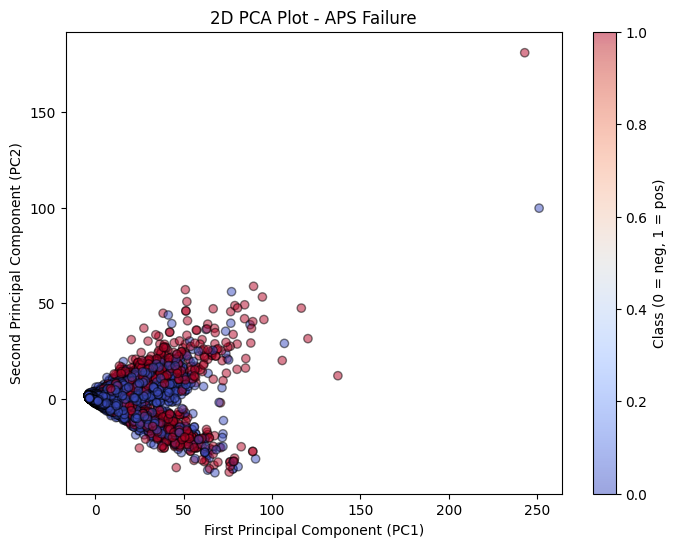

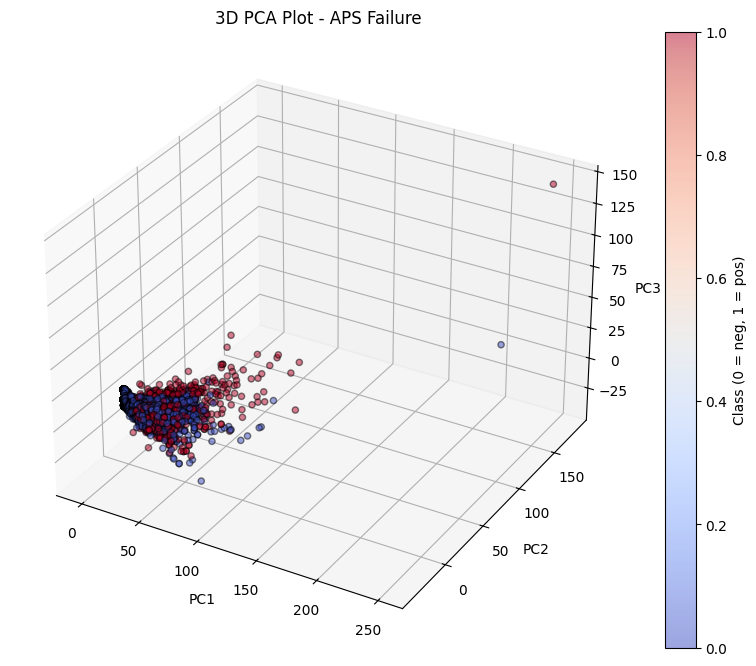

In [24]:
# TODO: maak een 2D- en 3D-plot van de voornaamste PCA-componenten van de
# trainingrijen van X_scaled (niet gecheckt, maar leerzaam).
# Targetlabels ophalen uit train (en eventueel test als die er is)
y_train = train["class"]
y_test = test["class"] if "class" in test.columns else None

if y_test is not None:
  y_all = pd.concat([y_train, y_test], ignore_index=True)
else:
  y_all = y_train

# Converteer string labels ("neg" / "pos") naar numerieke codes (0 en 1)
y_numeric = pd.factorize(y_all)[0]

# --- 2D PCA Plot ---
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
scatter_2d = plt.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y_numeric,
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.5,
)
plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("2D PCA Plot - APS Failure")
plt.colorbar(scatter_2d, label="Class (0 = neg, 1 = pos)")
plt.show()

# --- 3D PCA Plot ---
pca_3d = PCA(n_components=3)
X_pca_3d = pca_3d.fit_transform(X_scaled)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection="3d")
scatter_3d = ax.scatter(
    X_pca_3d[:, 0],
    X_pca_3d[:, 1],
    X_pca_3d[:, 2],
    c=y_numeric,
    cmap="coolwarm",
    edgecolor="k",
    alpha=0.5,
)

ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("3D PCA Plot - APS Failure")
fig.colorbar(scatter_3d, label="Class (0 = neg, 1 = pos)")
plt.show()

## Meerkeuzevragen

### Vraag 1 — Standaardiseren
Waarom moet je de features **standaardiseren** vóór je PCA toepast?

- **A)** Omdat PCA alleen werkt op gehele getallen.
- **B)** Omdat features op verschillende schalen anders onevenredig veel gewicht krijgen en de PCA dan vooral de grote schalen weerspiegelt.
- **C)** Omdat standaardiseren het aantal features vermindert.
- **D)** Omdat standaardiseren automatisch 95% van de variantie behoudt.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_scaling`.

### Vraag 2 — n_components=0.95
Wat betekent `PCA(n_components=0.95)`?

- **A)** Het model houdt 95 van de oorspronkelijke features over.
- **B)** Het model houdt 95% van de datapunten over.
- **C)** Het model kiest het kleinste aantal componenten dat samen minstens 95% van de variantie verklaart.
- **D)** Het model kiest altijd exact 95 componenten.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_95`.


In [ ]:
# Vraag 1: antwoord_scaling = "A", "B", "C" of "D"
antwoord_scaling = "B"

# Vraag 2: antwoord_95 = "A", "B", "C" of "D"
antwoord_95 = "C"
